# Predicting Low-Carbon Hours for Data-Center Computing

**Course:** AC209A  

**Canvas project group:** 14 

**Group members:** Minh-Thy Tyler, Gabe Gonzalez, Noah Schiro

## 1. Getting the Data

We obtained the PJM balancing authority Excel file from the EIA
Hourly Electric Grid Monitor.

Source: https://www.eia.gov/electricity/gridmonitor/knownissues/xls/PJM.xlsx

Download date: November 2 2026

The original file is stored locally at `data/raw/PJM.xlsx`.
We will inspect its sheets and date coverage before selecting our
proposed study period of January 2022 through December 2025.

In [1]:
# packages
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_path = Path("../data/raw/PJM.xlsx")

#inspecing available sheets before choosing which ones to load 
excel_file = pd.ExcelFile(data_path)
print("Available sheets:", excel_file.sheet_names)

Available sheets: ['Published Hourly Data', 'Published Daily Data', 'BA Full Names', 'Hourly Charts', 'Daily Charts', 'Known Data Issues', 'Notes', 'Imbalance Thresholds', 'Range Thresholds']


In [3]:
#loading in hourly data
hourly_df = pd.read_excel(excel_file, sheet_name="Published Hourly Data")

In [4]:
#displaying first five rows
display(hourly_df.head())

#size of the entire downloaded Excel file
size_mb = data_path.stat().st_size / 1_000_000
print(f"Downloaded Excel file size: {size_mb:.2f} MB")

,BA,UTC time,Local date,Hour,Local time,Time zone,Generation only?,Demand forecast,Demand,Net generation,...,CO2 Emissions: OIL,CO2 Emissions: Other,CO2 Emissions Generated,CO2 Emissions Imported,CO2 Emissions Exported,CO2 Emissions Consumed,Positive Generation,Consumed Electricity,CO2 Emissions Intensity for Generated Electricity,CO2 Emissions Intensity for Consumed Electricity
0,PJM,2015-07-01 05:00:00,2015-07-01,1,2015-07-01 01:00:00,Eastern,N,29415.0,84024.0,83944.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,PJM,2015-07-01 06:00:00,2015-07-01,2,2015-07-01 02:00:00,Eastern,N,27687.0,79791.0,80091.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,PJM,2015-07-01 07:00:00,2015-07-01,3,2015-07-01 03:00:00,Eastern,N,26574.0,76760.0,77994.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,PJM,2015-07-01 08:00:00,2015-07-01,4,2015-07-01 04:00:00,Eastern,N,26029.0,74931.0,76820.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,PJM,2015-07-01 09:00:00,2015-07-01,5,2015-07-01 05:00:00,Eastern,N,26220.0,74368.0,76268.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Downloaded Excel file size: 114.54 MB


## 2. Understanding the data

In [5]:
#Loading in known issues and notes about our data to have more of a comprehensive understanding
issues_df = pd.read_excel(excel_file, sheet_name = "Known Data Issues")
notes_df = pd.read_excel(excel_file, sheet_name = "Notes")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [6]:
display(issues_df)
display(notes_df)

,BA,UTC time,Local date,Hour,Data issue,Local time,Time zone,Generation only?,DF,D,...,File 2,File D,File 0 Processed Date,File 1 Processed Date,File 2 Processed Date,File D Processed Date,File 0 issue,File 1 issue,File 2 issue,File D issue
0,PJM,2015-07-01 05:00:00,2015-07-01,1,0,2015-07-01 01:00:00,Eastern,N,29415.0,84024.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
1,PJM,2015-07-01 06:00:00,2015-07-01,2,0,2015-07-01 02:00:00,Eastern,N,27687.0,79791.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
2,PJM,2015-07-01 07:00:00,2015-07-01,3,0,2015-07-01 03:00:00,Eastern,N,26574.0,76760.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
3,PJM,2015-07-01 08:00:00,2015-07-01,4,0,2015-07-01 04:00:00,Eastern,N,26029.0,74931.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
4,PJM,2015-07-01 09:00:00,2015-07-01,5,0,2015-07-01 05:00:00,Eastern,N,26220.0,74368.0,...,PJMdaily1842015,NaN,2016-02-20,2015-07-02,2015-07-03,NaT,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99404,PJM,2026-11-02 01:00:00,2026-11-01,21,1,2026-11-01 20:00:00,Eastern,N,85814.0,NaN,...,NaN,NaN,2026-11-01,NaT,NaT,NaT,1,0,0,0
99405,PJM,2026-11-02 02:00:00,2026-11-01,22,1,2026-11-01 21:00:00,Eastern,N,82586.0,NaN,...,NaN,NaN,2026-11-01,NaT,NaT,NaT,1,0,0,0
99406,PJM,2026-11-02 03:00:00,2026-11-01,23,1,2026-11-01 22:00:00,Eastern,N,79297.0,NaN,...,NaN,NaN,2026-11-01,NaT,NaT,NaT,1,0,0,0
99407,PJM,2026-11-02 04:00:00,2026-11-01,24,1,2026-11-01 23:00:00,Eastern,N,77088.0,NaN,...,NaN,NaN,2026-11-01,NaT,NaT,NaT,1,0,0,0


,"The information submitted by reporting entities is preliminary data and is made available ""as-is"" by EIA. Neither EIA nor reporting entities are responsible for reliance on the data for any specific use.",Unnamed: 1
0,NaN,NaN
1,NaN,For more details see: About the EIA-930 data
2,NaN,NaN
3,Column,Description
4,BA,2-4 letter code that identifies the balancing ...
...,...,...
218,CO2 Emissions Consumed,CO2 emissions consumed by balancing authority ...
219,Positive Generation,The sum of reported generation (MWh) by energy...
220,Consumed Electricity,Consumed electricity (MWh) is calculated as th...
221,CO2 Emissions Intensity for Generated Electricity,CO2 emissions intensity for total generation (...


Looking at the data, each row in the 'Published Hourly Data' dataset represents one hourly observation for the PJM balancing authority. There are 108 columns, so we will not be discussing what each column represents individually, the relavanet columns that we will be using for our project describe the timestamp, electricity demand, generation, electricity exchanges, and estimated CO2 emissions and carbon intesnsity, along with any imputed and adjusted versions of the aformentioned measurements.

In [7]:
#number of rows and columns:
print("\nShape of table:")
print(f"Rows: {hourly_df.shape[0]:,}")
print(f"Columns: {hourly_df.shape[1]:,}")

#Column types and non-missing counts
print("\nHourly Data Info:")
hourly_df.info(show_counts=True)



Shape of table:
Rows: 99,409
Columns: 108

Hourly Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 99409 entries, 0 to 99408
Columns: 108 entries, BA to CO2 Emissions Intensity for Consumed Electricity
dtypes: datetime64[us](3), float64(101), int64(1), str(3)
memory usage: 81.9 MB


In [8]:
# summary statistics of numerical columns
hourly_df.select_dtypes(include="number").describe().T

,count,mean,std,min,25%,50%,75%,max
Hour,99409.0,12.500236,6.922492e+00,1.000000,7.000000,13.000000,19.000000,2.500000e+01
Demand forecast,99025.0,90665.298712,1.695529e+04,21905.000000,79393.000000,88238.000000,99950.000000,1.655570e+05
Demand,99142.0,133606.816919,8.480803e+06,56260.000000,80951.000000,89356.500000,101172.000000,2.147480e+09
Net generation,99117.0,136451.370613,8.480797e+06,57919.000000,83496.000000,92124.000000,104118.000000,2.147480e+09
Total interchange,99118.0,2909.377086,3.126764e+03,-8156.000000,1199.000000,2978.000000,4605.000000,5.901060e+05
...,...,...,...,...,...,...,...,...
CO2 Emissions Consumed,71017.0,32058.196950,9.277677e+03,-1506.393360,25123.548578,30180.900185,37375.739667,7.221896e+04
Positive Generation,71173.0,95406.649305,1.648786e+04,287.000000,83762.000000,92449.000000,104546.000000,1.642810e+05
Consumed Electricity,71020.0,91895.396860,1.673486e+04,-8442.000000,80066.750000,89106.000000,101299.500000,1.635450e+05
CO2 Emissions Intensity for Generated Electricity,71173.0,0.755716,9.855004e-02,0.062798,0.680945,0.748872,0.824168,1.080516e+00


In [9]:
#understanding data ranges in our data
print("Start:", hourly_df["UTC time"].min())
print("End:", hourly_df["UTC time"].max())

Start: 2015-07-01 05:00:00
End: 2026-11-02 05:00:00


## 3. Cleaning and preprocessing

### Creating separate subset for our study

We restrict the hourly PJM data to 2022 to 11/01/2026 to focus on recent grid conditions while retaining four complete years of seasonal variation. This period provides a manageable dataset for chronological training, validation, and testing. Recent growing electricity demand from data centers is the reason we chose this range. This dataset also contains 108 columns. For the scope of this milestone, we focus our preprocessing on 22 columns that we believe are relevant to our project.These columns include timestamps, potential predictors, and candidate target variables. This selection is by no means permanent, and we may decided to include additional predictors as we start to evaluate our models. 

In [10]:
local_dates = pd.to_datetime(hourly_df ["Local date"])

keep_cols = [
    "UTC time",
    "Local date",
    "Hour",
    "Demand forecast",
    "Demand",
    "Net generation",
    "Total interchange",
    "NG: COL",
    "NG: NG",
    "NG: NUC",
    "NG: OIL",
    "NG: WND",
    "NG: SUN",
    "NG: WAT",
    "CO2 Emissions Intensity for Generated Electricity",
    "CO2 Emissions Intensity for Consumed Electricity",
    "CO2 Emissions Generated",
    "CO2 Emissions Imported",
    "CO2 Emissions Exported",
    "CO2 Emissions Consumed",
    "Positive Generation",
    "Consumed Electricity"
]

pjm = hourly_df .loc[(local_dates >= "2022-01-01") & (local_dates <= "2026-11-01")].copy()

pjm_selected = pjm[keep_cols].copy()

print("Study-period rows and columns:", pjm_selected.shape)
print("First local date:", pjm_selected["Local date"].min())
print("Last local date:", pjm_selected["Local date"].max())

Study-period rows and columns: (42384, 22)
First local date: 2022-01-01 00:00:00
Last local date: 2026-11-01 00:00:00


In [11]:
missing = pd.DataFrame({"Missing count": pjm_selected.isna().sum(), "Missing percent": pjm_selected.isna().mean() * 100})

#show only columns with missing values, largest counts first
display(missing[missing["Missing count"] > 0].sort_values("Missing count", ascending=False))

,Missing count,Missing percent
CO2 Emissions Intensity for Consumed Electricity,261,0.615798
Consumed Electricity,256,0.604002
CO2 Emissions Consumed,256,0.604002
CO2 Emissions Exported,256,0.604002
CO2 Emissions Imported,244,0.575689
NG: NUC,184,0.434126
NG: SUN,184,0.434126
NG: COL,184,0.434126
NG: OIL,179,0.422329
NG: WND,179,0.422329


### Checking if missingness varies by year

In [12]:
years = pd.to_datetime(pjm["Local date"]).dt.year

missing_cols = missing.index[missing["Missing count"] > 0]

#calculating percent missing within each year
missing_by_year = (pjm[missing_cols].isna().groupby(years).mean() * 100)

display(missing_by_year.T)

Local date,2022,2023,2024,2025,2026
Demand forecast,0.262557,0.285388,0.546448,0.285388,0.655738
Demand,0.262557,0.285388,0.535064,0.285388,0.642077
Net generation,0.262557,0.285388,0.535064,0.285388,0.642077
Total interchange,0.262557,0.285388,0.535064,0.285388,0.642077
NG: COL,0.319635,0.285388,0.535064,0.319635,0.765027
NG: NG,0.262557,0.285388,0.535064,0.319635,0.765027
NG: NUC,0.319635,0.285388,0.535064,0.319635,0.765027
NG: OIL,0.262557,0.285388,0.535064,0.319635,0.765027
NG: WND,0.262557,0.285388,0.535064,0.319635,0.765027
NG: SUN,0.319635,0.285388,0.535064,0.319635,0.765027


Missing data rates are low across the years, although 2026 has the highest rate for some columns,  approximately 1.1%, compared with less than 1% in earlier years. We are investigating whether these missing values cluster in particular months or consecutive hours. This comparison alone does not establish whether the data are missing completely at random, missing at random, or missing not at random.

In [13]:
#keep only columns with missing values, excluding the grouping column
missing_cols = [
    col for col in pjm_selected.columns
    if col != "Hour" and pjm_selected[col].isna().any()]

# Percent missing in each column, grouped by hour of day
missing_by_hour = (pjm_selected[missing_cols].isna().groupby(pjm_selected["Hour"]).mean() * 100)

display(missing_by_hour)

,Demand forecast,Demand,Net generation,Total interchange,NG: COL,NG: NG,NG: NUC,NG: OIL,NG: WND,NG: SUN,NG: WAT,CO2 Emissions Intensity for Generated Electricity,CO2 Emissions Intensity for Consumed Electricity,CO2 Emissions Generated,CO2 Emissions Imported,CO2 Emissions Exported,CO2 Emissions Consumed,Positive Generation,Consumed Electricity
Hour,,,,,,,,,,,,,,,,,,,
1,0.396376,0.226501,0.226501,0.226501,0.283126,0.226501,0.283126,0.226501,0.226501,0.283126,0.226501,0.226501,0.792752,0.226501,0.736127,0.736127,0.736127,0.226501,0.736127
2,0.396376,0.396376,0.396376,0.396376,0.509626,0.453001,0.509626,0.453001,0.453001,0.509626,0.453001,0.453001,0.679502,0.453001,0.566251,0.622877,0.622877,0.453001,0.622877
3,0.396376,0.396376,0.396376,0.396376,0.509626,0.453001,0.509626,0.453001,0.453001,0.509626,0.453001,0.453001,0.679502,0.453001,0.566251,0.622877,0.622877,0.453001,0.622877
4,0.396376,0.396376,0.396376,0.396376,0.509626,0.453001,0.509626,0.453001,0.453001,0.509626,0.453001,0.453001,0.679502,0.453001,0.566251,0.622877,0.622877,0.453001,0.622877
5,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251
6,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251
7,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251
8,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251
9,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.396376,0.566251,0.396376,0.566251,0.566251,0.566251,0.396376,0.566251


In [14]:
hour_to_check = missing_by_hour.max(axis=1).idxmax()

display(pjm_selected.loc[pjm_selected["Hour"] == hour_to_check])

,UTC time,Local date,Hour,Demand forecast,Demand,Net generation,Total interchange,NG: COL,NG: NG,NG: NUC,...,NG: SUN,NG: WAT,CO2 Emissions Intensity for Generated Electricity,CO2 Emissions Intensity for Consumed Electricity,CO2 Emissions Generated,CO2 Emissions Imported,CO2 Emissions Exported,CO2 Emissions Consumed,Positive Generation,Consumed Electricity
64464,2022-11-07 05:00:00,2022-11-06,25,65901.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
73200,2023-11-06 05:00:00,2023-11-05,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
81936,2024-11-04 05:00:00,2024-11-03,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
90672,2025-11-03 05:00:00,2025-11-02,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
99408,2026-11-02 05:00:00,2026-11-01,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


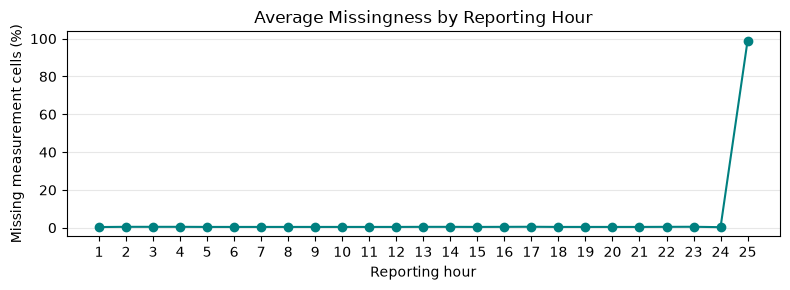

In [15]:
#excluding timestamps and the hour label
measurement_cols = pjm_selected.columns.drop(["UTC time", "Local date", "Hour"])

# Average missing percentage across measurements at each hour
missing_by_hour_avg = (pjm_selected[measurement_cols].isna().groupby(pjm_selected["Hour"]).mean().mean(axis=1) * 100)

plt.figure(figsize=(8, 3))
plt.plot(missing_by_hour_avg.index, missing_by_hour_avg.values, marker="o", color="teal")

plt.title("Average Missingness by Reporting Hour")
plt.xlabel("Reporting hour")
plt.ylabel("Missing measurement cells (%)")
plt.xticks(missing_by_hour_avg.index)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Missingness is low across reporting hours 1–24 for the selected variables. Reporting hour 25 has substantially higher missingness and will be investigated separately before a cleaning decision is made.

In [16]:
incomplete = pjm_selected[measurement_cols].isna().any(axis=1)

print("Total rows:", len(pjm_selected))
print("Incomplete rows:", incomplete.sum())
print(f"Percent affected: {incomplete.mean() * 100:.2f}%")

Total rows: 42384
Incomplete rows: 261
Percent affected: 0.62%


In [17]:
pjm_complete = pjm_selected.dropna(
    subset=measurement_cols
).copy()

print("Rows retained:", len(pjm_complete))

Rows retained: 42123


In [18]:
# Columns we use in modeling. Generated-electricity carbon intensity is our target.
# We only check these, so gaps in columns we don't use don't cost us extra days.
target = "CO2 Emissions Intensity for Generated Electricity"
check_cols = [
    "Demand forecast", "Demand", "Net generation", "Total interchange",
    "NG: COL", "NG: NG", "NG: NUC", "NG: OIL", "NG: WND", "NG: SUN", "NG: WAT",
    target,
]

local_day = pd.to_datetime(pjm_selected["Local date"]).dt.date

# Daylight-saving days have 23 or 25 local hours instead of 24
hours_per_day = local_day.value_counts()
dst_days = set(hours_per_day[hours_per_day != 24].index)

# Days with any missing value in the columns we use
missing_days = set(local_day[pjm_selected[check_cols].isna().any(axis=1)])

drop_days = dst_days | missing_days
pjm_clean = pjm_selected[~local_day.isin(drop_days)].copy()

print("DST days:", len(dst_days))
print("Days with missing data (not DST):", len(missing_days - dst_days), sorted(missing_days - dst_days))
print("Total days dropped:", len(drop_days), "of", local_day.nunique())
print("Rows before:", len(pjm_selected), "after:", len(pjm_clean))
print("Missing values left:", pjm_clean[check_cols].isna().sum().sum())

DST days: 10
Days with missing data (not DST): 7 [datetime.date(2022, 10, 1), datetime.date(2025, 7, 1), datetime.date(2026, 2, 18), datetime.date(2026, 3, 27), datetime.date(2026, 6, 25), datetime.date(2026, 8, 25), datetime.date(2026, 10, 15)]
Total days dropped: 17 of 1766
Rows before: 42384 after: 41976
Missing values left: 0


### Handling missing data

We dropped 17 of 1,766 days (about 1%). Ten are daylight-saving changeover days (two per year, including reporting hour 25 investigated above), where EIA's reporting is often incomplete; we drop all of them so every remaining day has exactly 24 hours. The other seven are missing values in the columns we use for a few hours each; on Oct 1, 2022 the missing coal and nuclear data also produced unrealistically low carbon intensities. We only check the columns we plan to model with (`check_cols`), so gaps in unused columns such as consumed-electricity emissions don't remove extra days. We chose not to impute because most of the gaps are entire days of our target variable, and imputing them would create fake labels. Because the gaps come from reporting issues rather than grid conditions, dropping them should not bias our results. From here on we use `pjm_clean`.

### Checking for unusual values

In [19]:
# Summary of the columns we use, after dropping missing-data days
display(pjm_clean[check_cols].describe().T)

# Negative values: only interchange can be negative (it means PJM is importing power)
print("Negative values per column:")
print((pjm_clean[check_cols] < 0).sum()[lambda s: s > 0])

,count,mean,std,min,25%,50%,75%,max
Demand forecast,41976.0,92661.222437,16435.762812,61016.000000,81278.500000,89516.500000,101842.500000,165557.000000
Demand,41976.0,93975.201401,15999.341641,56260.000000,82645.000000,90822.000000,103059.250000,162648.000000
Net generation,41976.0,97750.201163,16288.771833,66648.000000,85934.750000,94821.000000,107066.000000,164403.000000
Total interchange,41976.0,3089.703211,2366.867333,-4456.000000,1137.000000,2723.000000,4752.000000,13302.000000
NG: COL,41976.0,16072.041214,5900.017705,6198.000000,11504.750000,14803.500000,19254.250000,39903.000000
NG: NG,41976.0,41049.468625,9491.144806,4390.000000,34267.750000,39845.000000,46371.250000,75926.000000
NG: NUC,41976.0,31086.779850,2114.309918,16001.000000,29708.000000,31661.000000,32658.000000,46004.000000
NG: OIL,41976.0,476.694754,685.941410,32.000000,204.000000,226.000000,449.000000,11841.000000
NG: WND,41976.0,3557.199281,2378.704590,22.000000,1544.000000,3062.000000,5296.000000,10014.000000
NG: SUN,41976.0,1972.804865,3036.532754,0.000000,12.000000,97.000000,2899.000000,14206.000000


Negative values per column:
Total interchange    1684
dtype: int64


In [20]:
# Flag physically implausible values (thresholds chosen from each column's normal range)
demand_error = (pjm_clean["Demand"] - pjm_clean["Demand forecast"]).abs() / pjm_clean["Demand forecast"]
unusual = {
    "nuclear far above normal max (> 35,000 MW)": pjm_clean["NG: NUC"] > 35000,
    "nuclear suddenly halved (< 20,000 MW)": pjm_clean["NG: NUC"] < 20000,
    "natural gas missing (< 10,000 MW)": pjm_clean["NG: NG"] < 10000,
    "demand more than 25% off its forecast": demand_error > 0.25,
}

day = pd.to_datetime(pjm_clean["Local date"]).dt.date
error_days = set()
for reason, mask in unusual.items():
    print(f"{reason}: {mask.sum()} hours on {sorted(set(day[mask]))}")
    error_days |= set(day[mask])

pjm_clean = pjm_clean[~day.isin(error_days)].copy()
print("\nError days dropped:", len(error_days))
print("Rows left:", len(pjm_clean), "| days left:", pjm_clean["Local date"].nunique())

nuclear far above normal max (> 35,000 MW): 24 hours on [datetime.date(2022, 9, 30)]
nuclear suddenly halved (< 20,000 MW): 5 hours on [datetime.date(2022, 2, 11)]
natural gas missing (< 10,000 MW): 5 hours on [datetime.date(2023, 11, 2)]
demand more than 25% off its forecast: 7 hours on [datetime.date(2023, 8, 15), datetime.date(2024, 11, 21)]

Error days dropped: 5
Rows left: 41856 | days left: 1744


**Unusual values.** We checked each variable for impossible values and extreme outliers and examined the surrounding hours. Several extremes are real and kept: negative interchange (PJM importing power), zero solar at night, record summer demand in June 2025 and summer 2026 (the demand forecast predicted these peaks too), and oil generation spikes during Winter Storm Elliott (Dec 2022) and other extreme-weather events, when oil peaker plants run.

A standard outlier check (values more than three interquartile ranges beyond the quartiles) flagged no values in carbon intensity and almost none in the other variables, apart from one demand hour (the June 2025 heat-wave peak). It flagged 29 nuclear hours, all on Feb 11 and Sep 30, 2022, which we identified as errors. It also flagged many oil and solar hours, but these are real: oil plants run mainly during extreme weather and solar is zero at night, so normal values look extreme by comparison. We therefore did not apply a blanket outlier rule, and instead examined flagged values individually and wrote targeted checks for the errors we found.

We found five days with data errors and dropped them:
- **Feb 11, 2022:** nuclear output halves for a few hours and then immediately returns, which nuclear plants do not do.
- **Sep 30, 2022:** nuclear output stays about 12,000 MW above its normal maximum all day.
- **Nov 2, 2023:** natural gas generation is missing for several hours.
- **Aug 15, 2023:** demand jumps far above its forecast and then falls by exactly the same amount every hour, an artificial straight-line fill.
- **Nov 21, 2024:** demand drops 40% for one hour while generation stays flat.

The first three distort carbon intensity directly. We drop whole days to stay consistent with our missing-data rule. In total we removed 22 of 1,766 days (about 1.2%).